# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

In [2]:
import json

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

# Data Creation:

## Havest Wikipedia pages with tables:

In [91]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiHarvester
# Initialize Wikipedia harvester
harvester = WikiHarvester()
# Run Phase 1 - Harvesting titles based on keywords
harvester.run_complete_harvest()
# Run Phase 2 - Filtering pages for tables
await harvester.filter_pages_async()

Harvesting Pages By Keywords:   0%|          | 0/233 [00:00<?, ?keyword/s]


TOTAL UNIQUE TITLES COLLECTED: 167913



Method,Keyword,Count
Prefix,List of cities,1537
Prefix,List of countries,1278
Prefix,List of towns,501
Prefix,List of villages,483
Prefix,List of districts,375
Prefix,List of municipalities,1021
Prefix,List of communes,194
Prefix,List of counties,259
Prefix,List of provinces,84
Prefix,List of territories,22


Filtering Pages with Tables:   0%|          | 0/167913 [00:00<?, ?page/s]


TOTAL PAGES WITH TABLES COLLECTED: 62306



In [93]:
save_json("table_titles", harvester.valid_titles)

In [3]:
table_titles = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/table_titles.json")

## Parse and filter Wikipedia tables:

In [271]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

Pre-processing: cluster similar pages and discard similarities ---> 6426 pages discarded.


Extracting Tables:   0%|          | 0/55880 [00:00<?, ?Page/s]

Starting Extraction: 55880 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 32076 OUT OF 55880 (57.4%)


Filtering & Cleaning:   0%|          | 0/94101 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      94101
Dropped (Bad Headers):     8435
Dropped (Cell too long):   2841
Dropped (Repeat Rows):     1783
Short tables found:        39837
Unique source pages:       16940
Final sampled (1/page):    16940
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------

══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Rank,Player,Career,Caps,Goals
0,1,Christine Sinclair,2000–2023,331,190
1,2,Sophie Schmidt,2005–2023,226,20
2,3,Diana Matheson,2003–2021,206,19
3,4,Desiree Scott,2010–2025,188,0
4,5,Rhian Wilkinson,2003–2017,181,7
5,6,Kadeisha Buchanan,2013–present,154,6
6,7,Ashley Lawrence,2013–present,151,8
7,7,Jessie Fleming,2013–present,151,20
8,9,Brittany Baxter,2002–2014,132,5
9,9,Andrea Neil,1991–2007,132,24



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Manchester City F.C. 3–2 Queens Park Rangers F.C. > Match > Statistics
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Statistic,Manchester City,Queens Park Rangers
0,Goals scored,3,2
1,Possession,81.3%,18.7%
2,Shots on target,15,3
3,Shots off target,10,0
4,Blocked shots,19,0
5,Corner kicks,19,0
6,Fouls,4,7
7,Tackles,15,22
8,Offsides,1,1
9,Yellow cards,2,1



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Swinburne University of Technology > Notable people > Academics and staff
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Member,Executive team,Period
0,Pascale Quester,Vice-Chancellor,2020–present
1,Chris Pilgrim,Pro Vice-Chancellor (Academic),
2,Tara Magdalinski,Pro Vice-Chancellor (Education and Quality),
3,Sarah Maddison,Pro Vice-Chancellor (Academic Innovation and C...,
4,Bronwyn Fox,Deputy Vice-Chancellor (Research and Enterprise),
5,Beth Webster,Pro Vice-Chancellor (Research Policy and Impact),
6,Qing-Lon Han,Pro Vice-Chancellor (Research Quality),
7,Alan Kin-Tak Lau,Pro Vice-Chancellor (International Research De...,
8,Blair Kuys,Dean of the School of Design and Architecture,
9,Matthew Bailes,Director of the Data Science Research Institut...,


## Create Potential Entity Groups:

In [7]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 1000))
await group_constructor.get_groups()

🚀 Grouping 1000 tables using Entity-Focus logic...


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/1000 [00:00<?, ?it/s]


════════════════════════════════════════════════════════════════════════════════
                               📊 GROUPING REPORT                                
════════════════════════════════════════════════════════════════════════════════
  ✅ Valid Groups:   864
  ❌ Invalid Tables: 136
════════════════════════════════════════════════════════════════════════════════

✨ SAMPLE VALID NAMES:
  → Ports and harbours in Tanzania
  → Chart performance for Carver City in 2009
  → Filmfare Awards received by Atif Aslam

────────────────────────────────────────────────────────────────────────────────
                     🕵️ REJECTION DEBUGGER (Random Sample)                      
────────────────────────────────────────────────────────────────────────────────

[TABLE]: Mesa Grande Band of Diegueno Mission Indians > Reservation > Demographics (Mesa Grande Reservation, California – Racial and ethnic composition Note: the US Census treats Hispanic/Latino as an ethnic category. This table exclud

In [12]:
for sample in random.sample(group_constructor.valid_tables, 25):
    print(f"Group name: {sample['Group name']}")
    print(f"Wikipedia page: {sample['Wikipedia link']}")
    print(f"Entity column: {sample['Entity column']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Rankings of Steve Williams in the 200 meters
Wikipedia page: https://en.wikipedia.org/wiki/Steve_Williams_(sprinter)#Rankings
Entity column: Year


,Year,World rank,US rank
0,1972,-,6th
1,1973,1st,1st
2,1974,6th,2nd
3,1975,2nd,1st
4,1976,3rd,2nd
5,1977,5th,2nd
6,1978,6th,2nd
7,1979,-,-
8,1980,4th,1st




Group name: Highest-grossing Hong Kong films of 2019
Wikipedia page: https://en.wikipedia.org/wiki/List_of_Hong_Kong_films_of_2019#Box_office
Entity column: Title


,Rank,Title,Distributor,Domestic gross
0,1,Integrity,Emperor Cinema,"HK$30,986,111"
1,2,Ip Man 4: The Finale,Mandarin Motion Pictures,"HK$28,983,160"
2,3,The White Storm 2: Drug Lords,Universe Films Distribution,"HK$24,373,233"
3,4,Still Human,Golden Scene Company Limited,"HK$19,201,830"
4,5,P Storm,Mandarin Motion Pictures,"HK$17,514,387"




Group name: Teams in the 1992–93 Manchester City F.C. season final league table
Wikipedia page: https://en.wikipedia.org/wiki/1992–93_Manchester_City_F.C._season#Final_league_table
Entity column: Team v t e


...

,Organization,Host city,Host country,Mission
0,Food and Agriculture Organization,Rome,Italy,Permanent Mission
1,International Civil Aviation Organization,Montreal,Canada,Permanent Mission
2,Organization of American States,"Washington, D.C.",United States,Permanent Mission
3,United Nations,New York City,United States,Permanent Mission
4,United Nations,Geneva,Switzerland,Permanent Mission
5,United Nations,Vienna,Austria,Permanent Mission
6,UNESCO,Paris,France,Permanent Delegation
7,World Trade Organization,Geneva,Switzerland,Permanent Mission




Group name: Judging components for figure skating disciplines at the 2022 Winter Olympics
Wikipedia page: https://en.wikipedia.org/wiki/Figure_skating_at_the_2022_Winter_Olympics_–_Team_event#Judging
Entity column: Discipline


,Discipline,Short program or Rhythm dance,Free skate or Free dance
0,Men,1.0,2.0
1,Women,0.8,1.6
2,Pairs,0.8,1.6
3,Ice dance,0.8,1.2




Group name: Highest-grossing Spanish films of 2008
Wikipedia page: https://en.wikipedia.org/wiki/List_of_Spanish_films_of_2008#Box_office
Entity column: Title


,Rank,Title,Distributor,Admissions,Domestic gross ( € )
0,1,The Oxford Murders ( Los crímenes de Oxford ),Warner Bros.,1421063,8201220.76
1,2,Mortadelo and Filemon. Mission: Save the Plane...,Zeta Audiovisual,1363275,7706810.77
2,3,Vicky Cristina Barcelona,Warner Bros.,1240343,7459286.88
3,4,Che ( Che. El argentino ),Hispano Foxfilm,1161635,6830886.78
4,5,Asterix at the Olympic Games ( Astérix en los ...,Tripictures,1051286,5905546.01
5,6,Chef's Special ( Fuera de carta ),Warner Bros.,898186,5107626.42
6,7,The Blind Sunflowers ( Los girasoles ciegos ),Alta Classics,710318,4073176.61
7,8,Transsiberian,Sociedad General de Cine,393453,2348860.83
8,9,The El Escorial Conspiracy ( La conjura de El ...,Sony,318580,1845819.84
9,10,Carlitos and the Field of Dreams ( Carlitos y...,Hispano Foxfilm,258345,1401541.26


## Create FanOut-style Questions out of the Entity Groups:

### Rule-Based Strategy Candidate Selection:

In [419]:
from knowledge_maze.create_dataset.create_questions.question_generation import StrategySelector

selector = StrategySelector(group_constructor.valid_tables)
selector.get_strategies()

Sanitizing tables:   0%|          | 0/864 [00:00<?, ?it/s]

Slicing strategy views:   0%|          | 0/864 [00:00<?, ?it/s]


✅ Strategy Selection Complete.

═══════════════════════════════════════════════════════
📊 STRATEGY SELECTION SUMMARY
-------------------------------------------------------
✅ Groups Passed:     795
❌ Groups Discarded:  69
📈 Success Rate:      92.0%
-------------------------------------------------------
Strategy Distribution (Top 4 per table):
  - UNIQUE_DIVERSITY          : 437
  - EXTREME_TEMPORAL          : 376
  - COUNT_TOTAL               : 304
  - FILTER_COUNT_TEMPORAL     : 255
  - FREQUENCY_MODE            : 227
  - CATEGORICAL_FILTER_LOOKUP : 218
  - COMPARATIVE_DIFFERENCE    : 172
  - AGGREGATION               : 172
  - EXTREME_NUMERICAL         : 161
  - TOP_K_RANKING             : 143
  - FILTER_COUNT_NUMERICAL    : 138
-------------------------------------------------------
POSSIBLE STRATEGIES  | GROUP COUNT  | PERCENTAGE
-------------------------------------------------------
#1                   | 91           |      11.4%
#2                   | 64           |       8.1

In [320]:
selector.debug_strategy_samples("FREQUENCY_MODE")

Found 227 total tables with this strategy. Showing 5 random samples.



🔗 Source: https://en.wikipedia.org/wiki/List_of_diplomatic_missions_of_Cape_Verde#Current_missions


,Host country,Mission
0,Angola,Embassy
1,Angola,Consulate
2,Ethiopia,Embassy
3,Guinea-Bissau,Embassy
4,Morocco,Embassy
5,Morocco,Consulate-General
6,Nigeria,Embassy
7,São Tomé and Príncipe,Embassy
8,Senegal,Embassy


🔗 Source: https://en.wikipedia.org/wiki/List_of_awards_and_nominations_received_by_Katherine_Kelly#British_Soap_Awards


,Nominated for,Category
0,Coronation Street,Best Actress
1,Coronation Street,Best Comedy Performance
2,Coronation Street,Best On-Screen Partnership (with David Neilson )
3,Coronation Street,Best Actress
4,Coronation Street,Best On-Screen Partnership with ( Simon Gregson )
5,Coronation Street,Sexiest Female
6,Coronation Street,Best Actress
7,Coronation Street,Best On-Screen Partnership (with Simon Gregson)
8,Coronation Street,Best Actress
9,Coronation Street,Best On-Screen Partnership (with Simon Gregson)


...

,Opponent,Site
0,Kent State *,"Three Rivers Stadium Pittsburgh, PA"
1,at Bowling Green *,"Doyt Perry Stadium Bowling Green, OH"
2,Penn State *,"Three Rivers Stadium Pittsburgh, PA ( rivalry )"
3,Rutgers,"Three Rivers Stadium Pittsburgh, PA"
4,at Syracuse,"Carrier Dome Syracuse, NY ( rivalry )"
5,Boston College,"Three Rivers Stadium Pittsburgh, PA"
6,at No. 2 Virginia Tech,"Lane Stadium Blacksburg, VA"
7,North Carolina *,"Three Rivers Stadium Pittsburgh, PA"
8,at No. 2 Miami (FL),"Miami Orange Bowl Miami, FL"
9,at Temple,"Veterans Stadium Philadelphia, PA"


🔗 Source: https://en.wikipedia.org/wiki/List_of_species_that_have_landed_on_the_Moon#List


,Species,Quantity
0,Human,12
1,Silkworm,1+
2,Fruit fly,1+
3,Arabidopsis,1+
4,Cotton,1+
5,Potato,1+
6,Rapeseed,1+
7,Yeast,1+
8,Bacteria,1+
9,Tardigrade,1000+


🔗 Source: https://en.wikipedia.org/wiki/2021–22_Exeter_City_F.C._season#Transfers


,Name,Fee
0,Josh Coley,Undisclosed
1,Jevani Brown,Free transfer
2,Scott Brown,Free transfer
3,George Ray,Free transfer
4,Callum Rowe,Free transfer
5,Sam Nombe,Undisclosed
6,Pierce Sweeney,Free transfer
7,Timothée Dieng,Free transfer
8,Jonathan Grounds,Free transfer
9,Colin Daniel,Free transfer


### Model-Based Question Generation:

In [488]:
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector, QuestionGenerator

generator = QuestionGenerator(selector.updated_data,
                              strategy_definitions=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
await generator.generate_questions()

🚀 Starting Question Generation for 795 tables...
--- Round 1: Processing 795 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/795 [00:00<?, ?it/s]

--- Round 2: Processing 8 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/8 [00:00<?, ?it/s]

--- Round 3: Processing 2 tables ---


...

-----------------------------------------------------------------

[2] Table: Albums by 1910 Fruitgum Company
    Original Data: https://en.wikipedia.org/wiki/1910_Fruitgum_Company#Discography
    Strategy Attempted: FREQUENCY_MODE
    Rejection Reason:   There is a tie for the most frequent value due to multiple albums having a Billboard 200 ranking of '–', which does not provide a clear mode.
    Table Data:


,Album,Billboard 200
0,Simon Says,162
1,"1, 2, 3, Red Light",163
2,Goody Goody Gumdrops,–
3,Indian Giver,147
4,Hard Ride,–
5,Juiciest Fruitgum,–
6,Juiciest Hits,–
7,Bubblegum Goodies,–
8,A Golden Classics Edition,–
9,The Best of the 1910 Fruitgum Company: Simon Says,–


-----------------------------------------------------------------

[3] Table: Notable former players of USAFA Team Handball
    Original Data: https://en.wikipedia.org/wiki/USAFA_Team_Handball#Notable_former_players
    Strategy Attempted: FILTER_COUNT_TEMPORAL
    Rejection Reason:   Only 1 row found per graduation year, cannot establish a meaningful range for counting.
    Table Data:


,Name,Class
0,Bob Djokovich,1978
1,Tom Schneeberger,1978
2,Kathy Callaghan,1984
3,David W. Allvin,1986
4,David DeGraaf,1993
5,Andrew Donlin,2015


-----------------------------------------------------------------


## Question Validation:

### Model-Based Question Validator (Gemini 2.5 Flash):

In [493]:
from knowledge_maze.create_dataset.create_questions.question_validator import QuestionValidator
validator = QuestionValidator(random.sample(generator.valid_results, 200), load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
await validator.validate()

Manual Filtering:   0%|          | 0/200 [00:00<?, ?it/s]


════════════════════════════════════════
     📊 MANUAL FILTERING SUMMARY     
----------------------------------------
📊 Total Samples              | 200
✅ Approved                   | 183
❌ Missing Data Columns       | 15
❌ Missing Data               | 2
📈 Pass Rate:                 | 91.5%
----------------------------------------
      🚩 REJECTIONS BY STRATEGY      
----------------------------------------
CATEGORICAL_FILTER_LOOKUP    | 8
UNIQUE_DIVERSITY             | 7
TOP_K_RANKING                | 1
COUNT_TOTAL                  | 1
════════════════════════════════════════



Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/183 [00:00<?, ?it/s]


📊 VALIDATION SUMMARY
Total Samples:   183
✅ Approved:     172
❌ Rejected:     11
📈 Pass Rate:    94.0%
--------------------------------------------------
📉 REJECTIONS BY STRATEGY:
  - TOP_K_RANKING            : 4
  - FILTER_COUNT_TEMPORAL    : 2
  - COUNT_TOTAL              : 2
  - EXTREME_TEMPORAL         : 2
  - UNIQUE_DIVERSITY         : 1
--------------------------------------------------

🔍 TOP REJECTION EXAMPLES:

1. Strategy: FILTER_COUNT_TEMPORAL
   Question: How many wars involving Iceland occurred between the years 1500 and 2000?
   Wikipedia URL: https://en.wikipedia.org/wiki/List_of_wars_involving_Iceland#1500–2000
   Data: Wars involving Iceland from 1500 to 2000


,Conflict / Event,Date
0,Icelandic Reformation,1538–1550
1,Turkish Abductions,1627
2,Action of 16 May 1797,1797
3,Iceland in the Napoleonic Wars,1803–1815
4,Jørgen Jørgensen's Revolution,1809
5,Invasion of Iceland,1940
6,The Cod Wars,1958–1976


...

   🚩 Reason for rejection: The 'Location' column does not have repeating values, which is a requirement for the UNIQUE_DIVERSITY strategy. Each church has a unique address, so counting distinct locations would simply return the total number of churches, making the question trivial and not aligned with the strategy's intent to find a significantly smaller number of unique categories.

4. Strategy: TOP_K_RANKING
   Question: What were the top three teams in the 1928–29 Football League season based on their points?
   Wikipedia URL: https://en.wikipedia.org/wiki/1928–29_Stoke_City_F.C._season#Final_league_table
   Data: Teams in the 1928–29 Football League season


,Team v t e,Pts
0,Southampton,48
1,Notts County,47
2,Stoke City,46
3,West Bromwich Albion,46
4,Blackpool,45


   🚩 Reason for rejection: The strategy 'TOP_K_RANKING' requires that the value at position K must be strictly greater than the value at position K+1. In the provided data, if we sort by 'Pts' to find the top 3, the teams 'Notts County' (47 Pts) and 'West Bromwich Albion' (46 Pts) and 'Stoke City' (46 Pts) would be considered. However, 'West Bromwich Albion' and 'Stoke City' have the same points (46), which violates the strict inequality requirement for the K and K+1 positions (if K=2, K+1=3, and both have 46 points).

5. Strategy: COUNT_TOTAL
   Question: How many distinct political parties are there in Micronesia by country?
   Wikipedia URL: https://en.wikipedia.org/wiki/List_of_political_parties_in_Micronesia_by_country#List_of_countries
   Data: Political parties in Micronesia by country


,Country
0,Federated States of Micronesia
1,Guam
2,Kiribati
3,Marshall Islands
4,Nauru
5,Northern Mariana Islands
6,Palau


   🚩 Reason for rejection: The question asks about 'political parties' but the provided 'Table Data' only lists 'Country' names. There is no information about political parties to count.



### Manual Validation:

✅ Tagging Complete!


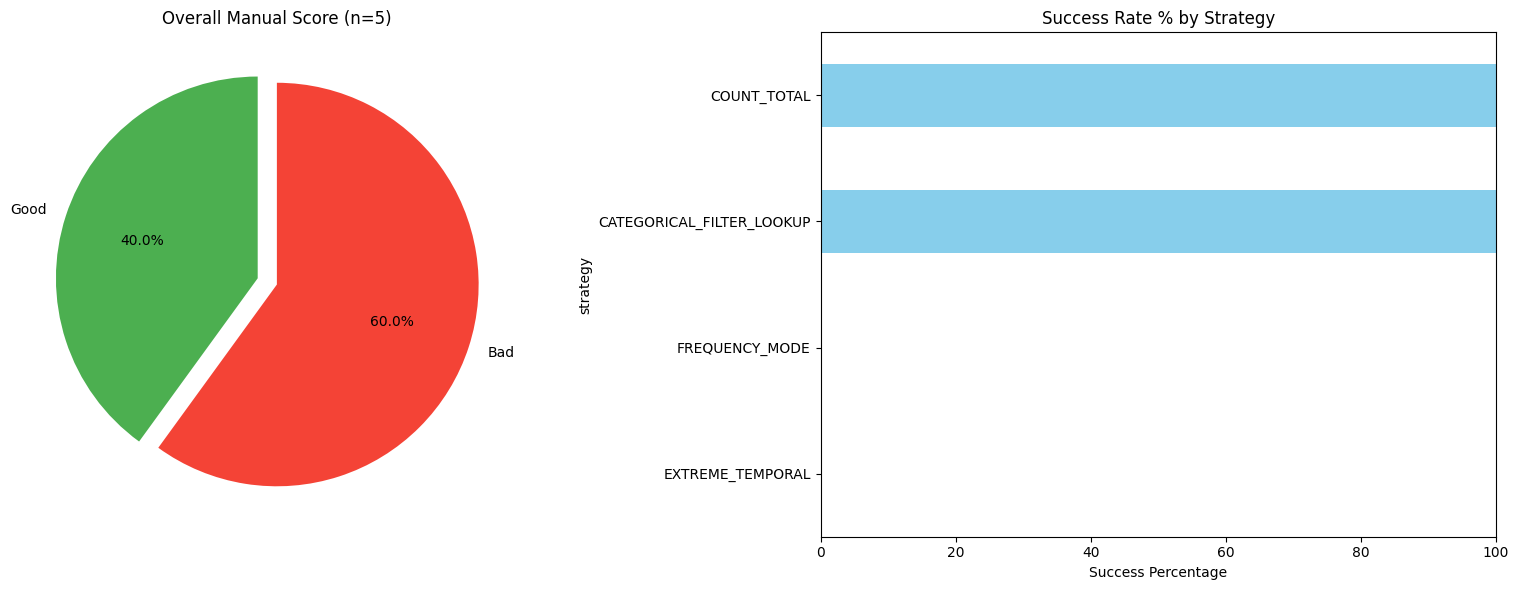

📊 Final Audit Result: 2/5 samples passed.


In [496]:
from knowledge_maze.create_dataset.create_questions.question_validator import ManualTagger
tagger = ManualTagger(generator.valid_results, load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
tagger.run(sample_size=5)

In [155]:
# EXTREME_NUMERICAL         : 
# EXTREME_TEMPORAL          : 
# COUNT_TOTAL               : 
# UNIQUE_DIVERSITY          : 
# CATEGORICAL_FILTER_LOOKUP : 
# FILTER_COUNT_TEMPORAL     : 
# FREQUENCY_MODE            : Success
# EXTREME_NUMERICAL         :
# AGGREGATION               : Partial - made a prompt fix for the scope of Top X in the aggragation. Still - No avg for some reason.
# FILTER_COUNT_NUMERICAL    :
# TOP_K_RANKING             : Success (need to set k to random somehow).
# COMPARATIVE_DIFFERENCE    :

import random
import pandas as pd

TARGET_STRATEGY = "AGGREGATION"
N = 5

matches = [
    sample
    for sample in validator.approved_data
    if sample.get("Selected strategy") == TARGET_STRATEGY
]

for sample in random.sample(matches, min(N, len(matches))):
    print(f"Group name: {sample['Group name']}")
    print(f"Strategy: {sample['Selected strategy']}")
    print(f"Question: {sample['Question']}")
    print(f"Wikipedia page: {sample['Wiki link']}")
    display(pd.DataFrame(sample['Relevant table data']))
    # display(pd.DataFrame(sample['Full table data']))
    print("\n")

Group name: Champions in Players Series Snooker
Strategy: AGGREGATION
Question: What is the total number of championships won by players in the Champions in Players Series Snooker?
Wikipedia page: https://en.wikipedia.org/wiki/Players_Series#Statistics


,Player,Total
0,Neil Robertson,5
1,Ronnie O'Sullivan,4
2,Judd Trump,3
3,Shaun Murphy,2
4,Mark Allen,2
5,John Higgins,2
6,Stephen Maguire,1
7,Mark Williams,1
8,Kyren Wilson,1




Group name: Former Lynx Air Fleet
Strategy: AGGREGATION
Question: What is the total number of aircraft in the former Lynx Air fleet?
Wikipedia page: https://en.wikipedia.org/wiki/Lynx_Air#Fleet


,Aircraft,Total
0,Boeing 737-700,7
1,Boeing 737-800,1
2,Boeing 737-800,1
3,De Havilland Canada DHC-6 Twin Otter,2
4,Piper PA-30 Twin Comanche,1
5,Airbus A320-200,1




Group name: Men's standings in the 1997–98 FIS Cross-Country World Cup
Strategy: AGGREGATION
Question: What is the total number of points accumulated by all competitors in the **1997–98 FIS Cross-Country World Cup**?
Wikipedia page: https://en.wikipedia.org/wiki/1997–98_FIS_Cross-Country_World_Cup#Men's_standings


,after all 12 events,Points
0,Thomas Alsgaard,790
1,Bjørn Dæhlie,678
2,Vladimir Smirnov,431
3,Mikhail Botvinov,330
4,Jari Isometsä,316
5,Fulvio Valbusa,310
6,Mika Myllylä,308
7,Erling Jevne,292
8,Silvio Fauner,273
9,Mathias Fredriksson,268




Group name: Growth of British railways
Strategy: AGGREGATION
Question: What is the total number of miles of British railways constructed by 1860?
Wikipedia page: https://en.wikipedia.org/wiki/History_of_rail_transport#History_by_country


,Year,Total miles
0,1830,98
1,1835,338
2,1840,1498
3,1845,2441
4,1850,6621
5,1855,8280
6,1860,10433




Group name: Highest-grossing Hong Kong films of 2019
Strategy: AGGREGATION
Question: What is the total domestic gross of the highest-grossing films in Hong Kong for 2019?
Wikipedia page: https://en.wikipedia.org/wiki/List_of_Hong_Kong_films_of_2019#Box_office


,Title,Domestic gross
0,Integrity,"HK$30,986,111"
1,Ip Man 4: The Finale,"HK$28,983,160"
2,The White Storm 2: Drug Lords,"HK$24,373,233"
3,Still Human,"HK$19,201,830"
4,P Storm,"HK$17,514,387"
